# K-Means clustering

Use a stratified 10,000-row sample from the shared 30,000 training rows.
Fit the shared 33-feature preprocessing on these 10,000 rows. Clustering and
all three scores use the full one-hot space; PCA is for visualization only.
Income labels enter stratified sampling and post-fit profiles only.
No test rows are used. Silhouette is computed on all 10,000 rows.

## 1. Environment and training data

In [1]:
from pathlib import Path
import sys
import time
import platform

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_info, threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=1)
cwd = Path.cwd()
repo_root = cwd if (cwd / "src/preprocessing.py").exists() else cwd.parent
assert (repo_root / "src/unsupervised_common.py").exists(), "Open from the repository root or notebooks/."
sys.path.insert(0, str(repo_root / "src"))
from unsupervised_common import (
    load_training_data, clustering_sample, prepare_clustering,
    evaluate_clustering, best_cluster_counts, pca_projection,
)
results_dir = repo_root / "results"
results_dir.mkdir(exist_ok=True)
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
data = load_training_data(repo_root)
print(f"Training rows: {len(data.X_train):,}; CV sample: {len(data.X_dev):,}; folds: {len(data.folds)}")

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4


Training rows: 172,459; CV sample: 30,000; folds: 5


## 2. Clustering sample and preprocessing

Stratified class counts are integers. The rate check allows one observation
of rounding error in 10,000 rows. The dense matrix retains every one-hot column
and can also be used for Ward linkage.

In [2]:
X_cluster, y_cluster = clustering_sample(data.X_dev, data.y_dev)
preprocessor, Z_cluster, preprocessing_seconds = prepare_clustering(X_cluster)
sample_info = pd.DataFrame([{
    "dev_rows": len(data.X_dev), "cluster_rows": len(X_cluster),
    "original_features": X_cluster.shape[1], "encoded_features": Z_cluster.shape[1],
    "dev_high_income_rate": data.y_dev.mean(), "sample_high_income_rate": y_cluster.mean(),
    "rate_tolerance": 1 / len(X_cluster), "preprocessing_seconds": preprocessing_seconds,
}])
sample_info.to_csv(results_dir / "kmeans_sample_info.csv", index=False)
display(sample_info)

,dev_rows,cluster_rows,original_features,encoded_features,dev_high_income_rate,sample_high_income_rate,rate_tolerance,preprocessing_seconds
0,30000,10000,33,436,0.086133,0.0861,0.0001,0.046651


## 3. Cluster counts and full-sample scores

In [3]:
K_VALUES = list(range(2, 11))
def make_kmeans(k):
    return KMeans(n_clusters=k, n_init=10, random_state=42)

scores, profiles, assignments = evaluate_clustering(
    Z_cluster, y_cluster, make_kmeans, K_VALUES
)
best_k = best_cluster_counts(scores)
scores.to_csv(results_dir / "kmeans_scores.csv", index=False)
best_k.to_csv(results_dir / "kmeans_best_k.csv", index=False)
profiles.to_csv(results_dir / "kmeans_cluster_profiles.csv", index=False)
membership = pd.DataFrame({"row_index": X_cluster.index})
for k in K_VALUES:
    membership[f"cluster_k_{k}"] = assignments[k]
membership.to_csv(results_dir / "kmeans_assignments.csv", index=False)
display(scores.round(6))
display(best_k)

Completed clustering k=2


Completed clustering k=3


Completed clustering k=4


Completed clustering k=5


Completed clustering k=6


Completed clustering k=7


Completed clustering k=8


Completed clustering k=9


Completed clustering k=10


,k,Silhouette,Calinski_Harabasz,Davies_Bouldin,fit_seconds,metrics_seconds,Silhouette_seconds,Calinski_Harabasz_seconds,Davies_Bouldin_seconds
0,2,0.161618,1781.091840,1.958712,0.478222,1.070480,1.038342,0.020817,0.011321
1,3,0.172045,1262.189932,1.791500,0.311743,0.700538,0.687064,0.007272,0.006202
2,4,0.171592,1049.738465,1.669318,0.366796,0.724418,0.709737,0.007733,0.006947
3,5,0.138762,905.487323,2.537462,0.578541,0.668629,0.650311,0.009158,0.009160
4,6,0.148099,943.634352,2.096836,0.610521,0.756848,0.738188,0.009446,0.009214
5,7,0.139720,886.206629,2.037258,0.901724,1.121591,1.087321,0.024292,0.009978
6,8,0.140581,874.662582,1.854485,0.752485,0.809135,0.782640,0.013384,0.013111
7,9,0.110925,825.008322,1.925317,0.603397,0.621493,0.595378,0.010474,0.015640
8,10,0.106152,768.632899,2.057475,0.683335,0.668359,0.645148,0.012021,0.011190


,metric,direction,k,value
0,Silhouette,max,3,0.172045
1,Calinski_Harabasz,max,2,1781.091840
2,Davies_Bouldin,min,4,1.669318


## 4. Score plots and post-fit income profiles

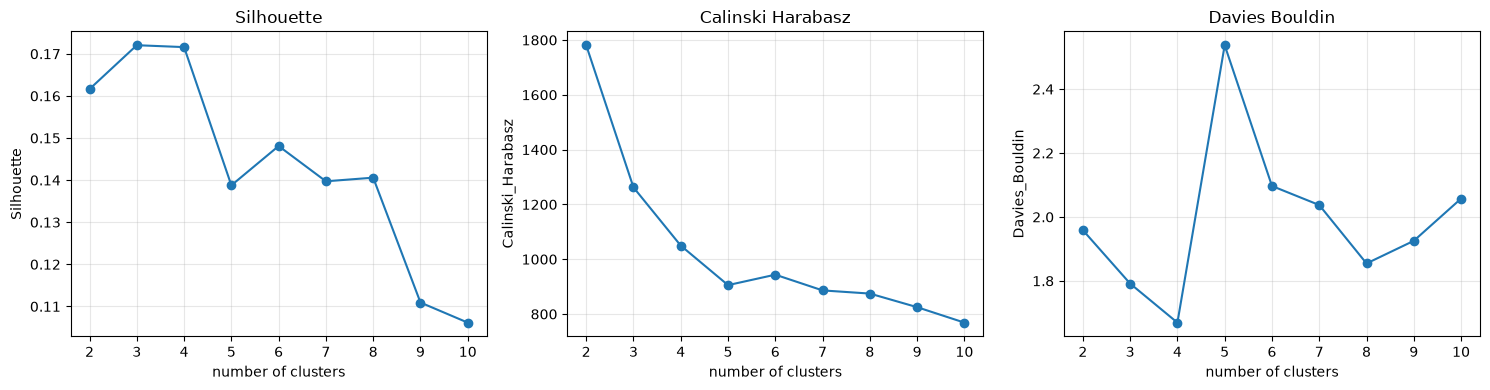

,k,cluster,count,high_income_rate
0,2,0,3227,0.018593
1,2,1,6773,0.118264
2,3,0,6528,0.107843
3,3,1,283,0.346290
4,3,2,3189,0.018501
5,4,0,6095,0.123544
6,4,1,685,0.045255
7,4,2,3199,0.018443
8,4,3,21,0.857143
9,5,0,2585,0.047582


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Silhouette", "Calinski_Harabasz", "Davies_Bouldin"]):
    ax.plot(scores["k"], scores[metric], marker="o")
    ax.set(title=metric.replace("_", " "), xlabel="number of clusters", ylabel=metric)
    ax.set_xticks(K_VALUES)
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
with pd.option_context("display.max_rows", None):
    display(profiles.round(6))

## 5. PCA visualization at the Silhouette-selected k

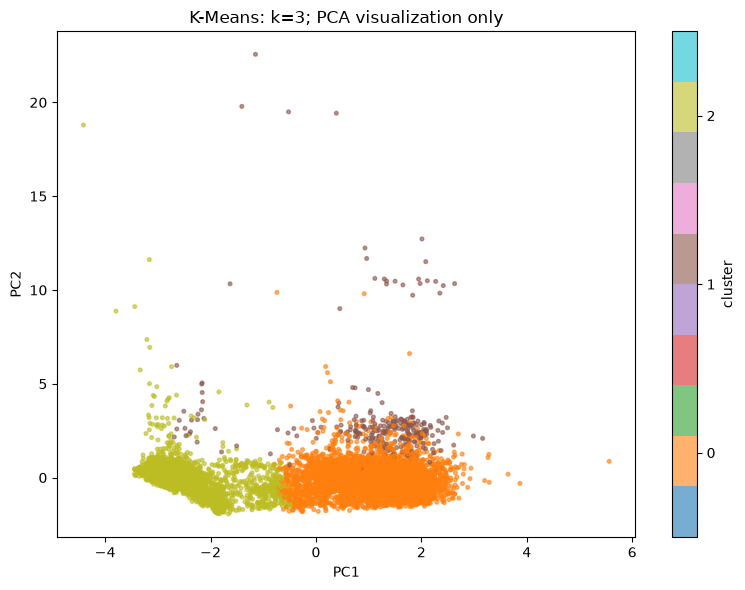

In [5]:
coordinates, pca = pca_projection(Z_cluster)
pd.DataFrame({"component": [1, 2], "explained_variance_ratio": pca.explained_variance_ratio_}).to_csv(
    results_dir / "kmeans_pca_variance.csv", index=False
)
def plot_clusters(k, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=assignments[k],
                        cmap="tab10", s=7, alpha=0.6, vmin=-0.5, vmax=k - 0.5)
    fig.colorbar(points, ax=ax, ticks=range(k), label="cluster")
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
    fig.tight_layout()
    plt.show()
silhouette_k = int(best_k.loc[best_k.metric == "Silhouette", "k"].iloc[0])
plot_clusters(silhouette_k, f"K-Means: k={silhouette_k}; PCA visualization only")

## 6. Optional common k for comparison with Ward linkage

The common k was set to 4 by the agreed rule in notebook 07.

,k,cluster,count,high_income_rate
5,4,0,6095,0.123544
6,4,1,685,0.045255
7,4,2,3199,0.018443
8,4,3,21,0.857143


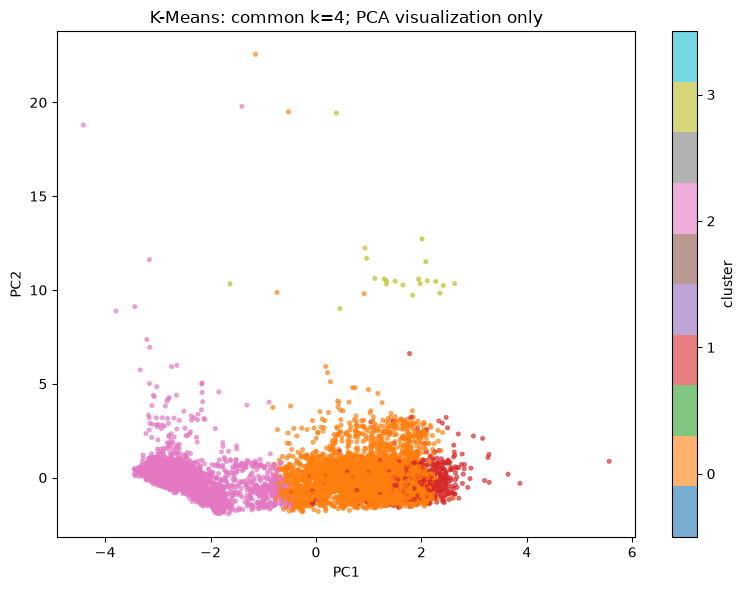

In [6]:
COMMON_K = 4
if COMMON_K is None:
    print("Common k is not yet decided.")
else:
    assert COMMON_K in K_VALUES
    display(profiles.loc[profiles.k == COMMON_K].round(6))
    plot_clusters(COMMON_K, f"K-Means: common k={COMMON_K}; PCA visualization only")

## 7. Final checks and execution time

In [7]:
assert len(data.X_dev) == 30_000 and len(data.folds) == 5
assert X_cluster.shape == (10_000, 33)
assert np.isclose(y_cluster.mean(), data.y_dev.mean(), atol=1 / 10_000, rtol=0)
assert scores.k.tolist() == list(range(2, 11)) and len(scores) == 9
assert np.isfinite(scores[["Silhouette", "Calinski_Harabasz", "Davies_Bouldin"]]).all().all()
assert len(profiles) == sum(K_VALUES)
assert profiles.groupby("k")["count"].sum().eq(10_000).all()
assert all(len(np.unique(assignments[k])) == k for k in K_VALUES)
assert set(X_cluster.index).issubset(set(data.X_dev.index))
assert all(item["num_threads"] == 1 for item in threadpool_info())
assert COMMON_K is None or COMMON_K in K_VALUES
total_seconds = time.perf_counter() - experiment_started
pd.DataFrame([{"total_seconds": total_seconds, "python": platform.python_version(),
               "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
               "native_threads": 1}]).to_csv(results_dir / "kmeans_execution.csv", index=False)
print("Final checks passed.")
print(f"Total execution time: {total_seconds:.2f} seconds")

Final checks passed.
Total execution time: 16.27 seconds
